# Step 3 — Subscription-Adapted RFM Segmentation

This dataset has no transaction dates, so classic Recency/Frequency (from
repeat purchase timestamps) doesn't apply. We substitute subscription
equivalents, each scored 1 (low) – 5 (high):

| RFM letter | Substituted with | Why |
|---|---|---|
| **R** (loyalty proxy) | `tenure` (months) | longer tenure scores higher |
| **F** (engagement proxy) | `NumServices` | more add-ons subscribed scores higher |
| **M** (monetary) | `MonthlyCharges` | higher recurring spend scores higher |

`MonthlyCharges` (not `TotalCharges`) is used for **M** deliberately:
`TotalCharges` is mechanically driven by tenure (longer-tenured customers
accumulate more regardless of spend rate), which would make R and M
redundant. `MonthlyCharges` isolates "how much do they pay per period" as an
independent signal.

**Input:** `data/cleaned_telco.csv`
**Output:** `data/segments.csv`, plus 2 charts rendered inline below

In [1]:
import os
import sys


def find_project_root(marker="requirements.txt"):
    path = os.getcwd()
    for _ in range(5):
        if os.path.exists(os.path.join(path, marker)):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not locate project root (looked for {marker})")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, os.path.join(PROJECT_ROOT, "scripts"))
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

PROJECT_ROOT = C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project


In [2]:
from plot_style import CATEGORICAL, CHURN_COLOR, INK_SECONDARY, apply_style

import matplotlib.pyplot as plt
import pandas as pd

CLEANED_PATH = os.path.join(PROJECT_ROOT, "data", "cleaned_telco.csv")
OUT_PATH = os.path.join(PROJECT_ROOT, "data", "segments.csv")

apply_style()

SEGMENT_ORDER = [
    "Champions",
    "Loyal, Low Engagement",
    "Price-Sensitive Risk",
    "Growing / Promising",
    "New / Low-Engagement",
    "Steady / Core",
]

## Scoring functions

In [3]:
def score_quantile(series, q=5):
    """Quantile score 1..q, falling back to fewer bins if the data has heavy ties."""
    ranked = series.rank(method="first")
    scored = pd.qcut(ranked, q, labels=range(1, q + 1))
    return scored.astype(int)


def score_num_services(n, max_n=6):
    return int(round(1 + (n / max_n) * 4))


def assign_segment(row):
    r, f, m = row["R_score"], row["F_score"], row["M_score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 4 and f <= 2:
        return "Loyal, Low Engagement"
    if f <= 2 and m >= 4:
        return "Price-Sensitive Risk"
    if r <= 2 and f >= 3 and m >= 3:
        return "Growing / Promising"
    if r <= 2 and f <= 2:
        return "New / Low-Engagement"
    return "Steady / Core"

## Compute R/F/M scores

In [4]:
df = pd.read_csv(CLEANED_PATH)

df["R_score"] = score_quantile(df["tenure"])
df["M_score"] = score_quantile(df["MonthlyCharges"])
df["F_score"] = df["NumServices"].apply(score_num_services)

print("R_score (tenure) distribution:\n", df["R_score"].value_counts().sort_index())
print("\nF_score (services) distribution:\n", df["F_score"].value_counts().sort_index())
print("\nM_score (monthly charges) distribution:\n", df["M_score"].value_counts().sort_index())

R_score (tenure) distribution:
 R_score
1    1409
2    1408
3    1409
4    1408
5    1409
Name: count, dtype: int64

F_score (services) distribution:
 F_score
1    2219
2    1999
3    1118
4    1423
5     284
Name: count, dtype: int64

M_score (monthly charges) distribution:
 M_score
1    1409
2    1408
3    1409
4    1408
5    1409
Name: count, dtype: int64


## Assign segments

In [5]:
df["RFM_Total"] = df["R_score"] + df["F_score"] + df["M_score"]
df["Segment"] = df.apply(assign_segment, axis=1)

seg_counts = df["Segment"].value_counts().reindex(SEGMENT_ORDER)
print("Segment counts:\n", seg_counts)
assert seg_counts.sum() == len(df), "Segment counts don't sum to total customers"

Segment counts:
 Segment
Champions                 994
Loyal, Low Engagement     986
Price-Sensitive Risk      731
Growing / Promising       394
New / Low-Engagement     1873
Steady / Core            2065
Name: count, dtype: int64


## Validate: does the adapted RFM track real churn?

If it weren't behaviorally meaningful, real churn wouldn't track it this cleanly.

In [6]:
seg_churn = df.groupby("Segment")["ChurnFlag"].mean().reindex(SEGMENT_ORDER) * 100
print("Churn rate by segment (%):\n", seg_churn.round(2))

Churn rate by segment (%):
 Segment
Champions                13.48
Loyal, Low Engagement     8.62
Price-Sensitive Risk     59.78
Growing / Promising      48.48
New / Low-Engagement     36.73
Steady / Core            16.17
Name: ChurnFlag, dtype: float64


## Save segments

In [7]:
keep_cols = ["customerID", "tenure", "NumServices", "MonthlyCharges", "TotalCharges",
             "R_score", "F_score", "M_score", "RFM_Total", "Segment", "Churn", "ChurnFlag"]
df[keep_cols].to_csv(OUT_PATH, index=False)
print(f"Wrote {len(df)} rows to {OUT_PATH}")

Wrote 7043 rows to C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project\data\segments.csv


## Chart: segment distribution

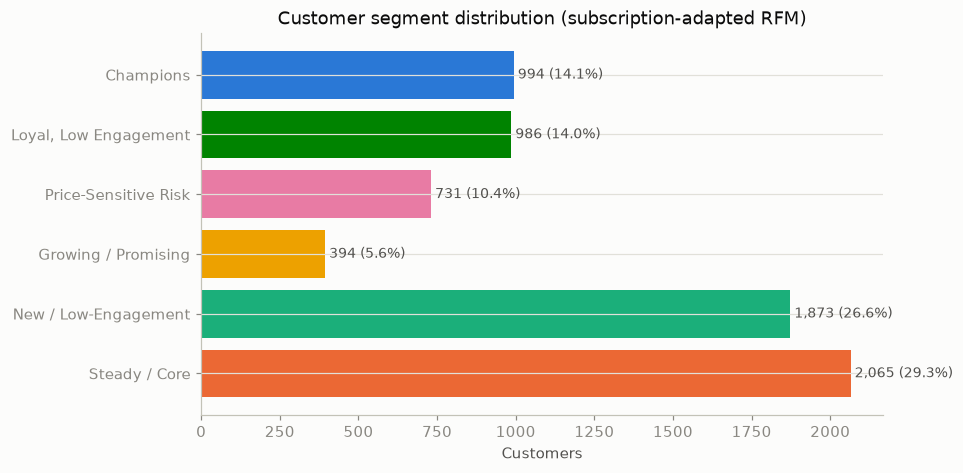

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = CATEGORICAL[:len(SEGMENT_ORDER)]
ax.barh(SEGMENT_ORDER, seg_counts.values, color=colors)
for i, v in enumerate(seg_counts.values):
    ax.text(v, i, f" {v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=9, color=INK_SECONDARY)
ax.set_title("Customer segment distribution (subscription-adapted RFM)")
ax.set_xlabel("Customers")
ax.invert_yaxis()
plt.show()

## Chart: real churn rate by segment

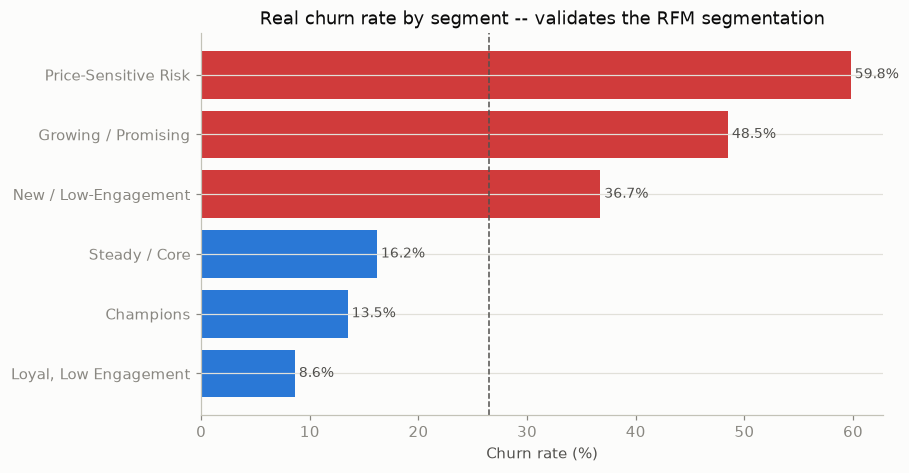

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
d = seg_churn.sort_values(ascending=True)
bar_colors = [CHURN_COLOR if v >= seg_churn.mean() else CATEGORICAL[0] for v in d.values]
ax.barh(d.index, d.values, color=bar_colors)
for i, v in enumerate(d.values):
    ax.text(v, i, f" {v:.1f}%", va="center", fontsize=9, color=INK_SECONDARY)
ax.axvline(df["ChurnFlag"].mean() * 100, color=INK_SECONDARY, linewidth=1, linestyle="--")
ax.annotate("overall avg", (df["ChurnFlag"].mean() * 100, -0.7), fontsize=8, color=INK_SECONDARY)
ax.set_title("Real churn rate by segment -- validates the RFM segmentation")
ax.set_xlabel("Churn rate (%)")
plt.show()